# Ball on flat: domain size and SlipPY's elastic kernel

**Case:** `validation/contact/hertz_point_grid_domain` (V-DRY-04), criterion P6 of the README.

The ball-on-flat contact is solved at the default spacing $h_0$ on domains of half-length 2, 4
and 8 $a$ along rolling, twice: with SlipPY's default frequency-domain kernel
(`use_frequency_domain=True`; the kernel is periodic, so the contact also feels images of its own
load) and with the spatial-domain kernel (`False`; the loads are zero-padded, no images). An
elastic half-space has no domain: once the contact is inside, a correct solution does not change
with the half-length.

The judge is `references.contact.hertz.hertz_point`. The sources give no number for this check
(Polonsky & Keer is not an FFT periodic-vs-padded study): P6 is the old study's criterion 4',
**[proposed]**: $p_0$ and $\delta$ change by less than 0.05 % between half-lengths, spatial
kernel. The frequency-domain arm is recorded only. `--smoke`: half-length 4 only (P6 not
evaluated).

In [1]:
import math
import sys

import matplotlib.pyplot as plt
from IPython.display import display
from axisforge.outputs._format import format_table, write_records_csv

from references.contact.hertz import hertz_point
from validation._support.convergence import RECORD_COLUMNS, sweep
from validation._support.figures import contact_plots
from validation._support.style import use_style

from construction import CASE, RESULTS, SPAN_X_LEVELS

use_style()                                       # house paper style (style/README.md)
SMOKE = "--smoke" in sys.argv                     # step-7 smoke run; a notebook runs every half-length
NAME = "03_kernel"
RESULTS.mkdir(exist_ok=True)                      # git-ignored (D-0020)
SPANS = (4.0,) if SMOKE else SPAN_X_LEVELS        # half-lengths along rolling in units of a [-]
KERNELS = {"freq": True, "spatial": False}        # label -> use_frequency_domain

JUDGE = hertz_point(CASE.r1, CASE.r2, CASE.E, CASE.nu, CASE.load)
A = JUDGE["s_x_m"]                                # circular contact: s_x = s_y = a [m]

## 1. Domain sweep with each kernel

Separate SlipPY output folders: the model names of the two sweeps are the same.

In [2]:
records = []
for label, use_frequency_domain in KERNELS.items():
    for r in sweep(CASE, ("composite",), (), SPANS, RESULTS / f"slippy_{label}",
                   use_frequency_domain=use_frequency_domain):
        a_meas = math.sqrt(r["s_x_m"] * r["s_y_m"])                  # radius of the measured area [m]
        records.append({**r, "kernel": label, "a_m": a_meas, "M": 2.0 * A / r["h_m"],
                        "eps_a": (a_meas - A) / A,
                        "eps_p0": (r["p0_Pa"] - JUDGE["p0_Pa"]) / JUDGE["p0_Pa"],
                        "eps_delta": (r["delta_m"] - JUDGE["delta_m"]) / JUDGE["delta_m"]})

print(format_table((("kernel", "kernel", "s"),) + RECORD_COLUMNS, records))
print()
print(format_table((("kernel", "kernel", "s"), ("span_x", "span_x [a]", "g"), ("M", "M", ".1f"),
                    ("eps_a", "eps a [%]", "+.4f", 100.0), ("eps_p0", "eps p0 [%]", "+.4f", 100.0),
                    ("eps_delta", "eps delta [%]", "+.4f", 100.0)), records))

 kernel      build   sweep  span_x [s_x]  h [um]  n_x  n_y  p0 [MPa]  err p0 [%]  err s_x [%]  err s_y [%]  err delta [%]  t [s]
-------  ---------  ------  ------------  ------  ---  ---  --------  ----------  -----------  -----------  -------------  -----
   freq  composite  domain             2  15.259   74   50   3187.57      +0.458       +0.313       +0.150         -1.598   0.62
   freq  composite  domain             4  15.259  146   50   3181.65      +0.272       +0.422       +0.137         +1.260   0.76
   freq  composite  domain             8  15.259  290   50   3180.13      +0.224       +0.454       +0.135         +6.281   0.43
spatial  composite  domain             2  15.259   74   50   3174.12      +0.035       +0.255       +0.255         +0.004   0.09
spatial  composite  domain             4  15.259  146   50   3174.12      +0.035       +0.255       +0.255         +0.004   0.07
spatial  composite  domain             8  15.259  290   50   3174.12      +0.035       +0.255    

## 2. Criteria

Per kernel and half-length: $a$, $p_0$, $\delta$ against the judge with P1's limits ($1/M$,
$M^{-3/2}$, 2 %, all **[proposed]**). The error computation of `01_ball_flat` is repeated here on
purpose: each notebook shows its own grading (no criteria helper in `_support`). P6: the largest
relative change of $p_0$ and of $\delta$ between consecutive half-lengths; graded on the spatial
kernel, recorded on the frequency kernel.

In [3]:
def row(cid, quantity, kernel, value, expected, err, limit, ok):
    """One criteria record; ``ok`` None means recorded only."""
    return {"id": cid, "quantity": quantity, "kernel": kernel, "value": value, "expected": expected,
            "err": err, "limit": limit, "result": "recorded" if ok is None else ("PASS" if ok else "FAIL")}


criteria = []
for label in KERNELS:
    arm = sorted((r for r in records if r["kernel"] == label), key=lambda r: r["span_x"])
    for r in arm:
        at = f" at span {r['span_x']:g} a"
        criteria += [
            row("P1", "a [proposed]" + at, label, r["a_m"], A, r["eps_a"], f"< {1 / r['M']:.4f}",
                abs(r["eps_a"]) < 1 / r["M"]),
            row("P1", "p0 [proposed]" + at, label, r["p0_Pa"], JUDGE["p0_Pa"], r["eps_p0"], f"<= {r['M'] ** -1.5:.5f}",
                abs(r["eps_p0"]) <= r["M"] ** -1.5),
            row("P1", "delta [proposed]" + at, label, r["delta_m"], JUDGE["delta_m"], r["eps_delta"], "<= 0.02",
                abs(r["eps_delta"]) <= 0.02),
        ]
    for key in ("p0_Pa", "delta_m"):
        if len(arm) < 2:
            criteria.append(row("P6", f"{key} change between half-lengths [proposed]", label, math.nan, 0.0,
                                math.nan, "< 0.0005", None))
            continue
        change = max(abs(b[key] / a[key] - 1.0) for a, b in zip(arm, arm[1:]))
        criteria.append(row("P6", f"{key} change between half-lengths [proposed]", label, change, 0.0, change,
                            "< 0.0005", change < 0.0005 if label == "spatial" else None))

print(format_table((("id", "ID", "s"), ("quantity", "quantity", "s"), ("kernel", "kernel", "s"),
                    ("value", "value", ".6g"), ("expected", "expected", ".6g"), ("err", "err [%]", "+.4f", 100.0),
                    ("limit", "limit", "s"), ("result", "result", "s")), criteria))
write_records_csv(RESULTS / f"{NAME}.csv", records)
write_records_csv(RESULTS / f"{NAME}_criteria.csv", criteria)

ID                                        quantity   kernel        value     expected  err [%]       limit    result
--  ----------------------------------------------  -------  -----------  -----------  -------  ----------  --------
P1                        a [proposed] at span 2 a     freq  0.000274931  0.000274296  +0.2315    < 0.0278      PASS
P1                       p0 [proposed] at span 2 a     freq  3.18757e+09  3.17302e+09  +0.4583  <= 0.00464      PASS
P1                    delta [proposed] at span 2 a     freq  1.16592e-05  1.18485e-05  -1.5976     <= 0.02      PASS
P1                        a [proposed] at span 4 a     freq  0.000275063  0.000274296  +0.2797    < 0.0278      PASS
P1                       p0 [proposed] at span 4 a     freq  3.18165e+09  3.17302e+09  +0.2718  <= 0.00464      PASS
P1                    delta [proposed] at span 4 a     freq  1.19978e-05  1.18485e-05  +1.2601     <= 0.02      PASS
P1                        a [proposed] at span 8 a     freq  0.0

## 3. Figures

The bridge errors (information: against SlipPY's `hertz_full`) along the domain sweep, one figure
per kernel.

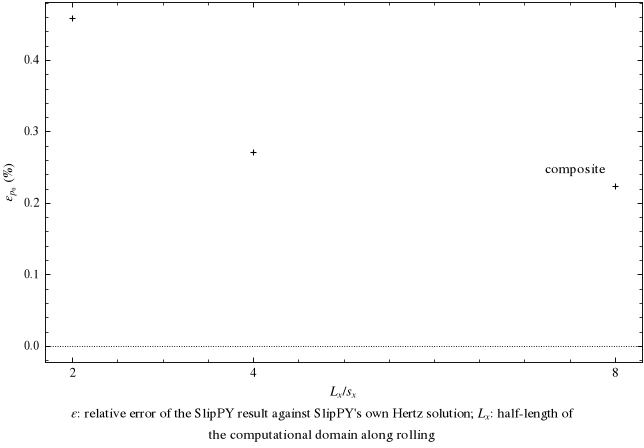

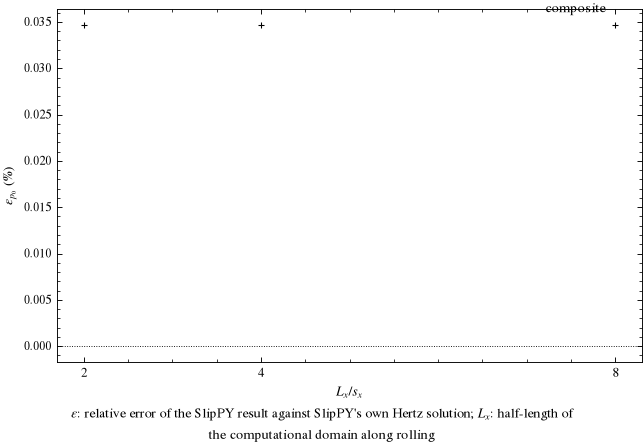

In [4]:
for label in KERNELS:
    fig = contact_plots.convergence([r for r in records if r["kernel"] == label], RESULTS / f"{NAME}_{label}.png")
    display(fig)                                  # notebook: shown inline; shell: its repr
    plt.close(fig)